John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [11]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
# library(ranger) # engine for random forest

# set random seed
set.seed(42)

Load data

In [12]:
data <- read_csv("../data/matching_opportunities.csv") %>%
    drop_na() # drop any row containing at least one NA value

Rows: 709 Columns: 64
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (63): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_M...
dttm  (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [13]:
# Model Inputs
model_columns <- c(
        "UST", 
        # "does_it_match",
        # "D_M1_M2", "D_M1_M3", "D_M1_M4", "D_M1_M5", "D_M1_M6",
        "M1_last_UST", "M2_last_UST", "M3_last_UST", "M4_last_UST", "M5_last_UST", "M6_last_UST", # TODO: These are categorical variables, how does this implementation of knn handle those?
        # "time_M1_last_song", "time_M2_last_song", "time_M3_last_song", "time_M4_last_song", "time_M5_last_song", "time_M6_last_song",
    	"time_since_M1_last_song", "time_since_M2_last_song", "time_since_M3_last_song", "time_since_M4_last_song", "time_since_M5_last_song", "time_since_M6_last_song" # did not include time since M1 last song because it is always 0
        # "time_rel_sunrise"
    )

In [14]:
# Set data types and select input columns
data <- data %>% 
    mutate(across(contains("UST"), ~ as.factor(.x)), 
        does_it_match = as.factor(does_it_match),
        number_of_matches = as.integer(number_of_matches)) %>%
    select(model_columns)

In [15]:
glimpse(data)

Rows: 428
Columns: 13
$ UST                     <fct> 0, 20, 3, 0, 13, 9, 8, 3, 116, 29, 10, 8, 3, 2…
$ M1_last_UST             <fct> 0, 20, 3, 3, 13, 9, 8, 3, 116, 29, 10, 8, 3, 2…
$ M2_last_UST             <fct> 0, 0, 8, 9, 0, 5, 16, 9, 3, 8, 8, 9, 3, 9, 16,…
$ M3_last_UST             <fct> 0, 20, 3, 0, 0, 8, 8, 8, 8, 8, 8, 9, 3, 0, 16,…
$ M4_last_UST             <fct> 0, 0, 9, 9, 0, 3, 3, 8, 9, 9, 9, 10, 10, 3, 0,…
$ M5_last_UST             <fct> 0, 0, 8, 0, 0, 0, 8, 0, 0, 10, 10, 8, 8, 20, 2…
$ M6_last_UST             <fct> 13, 13, 13, 13, 13, 8, 8, 8, 8, 8, 8, 3, 3, 0,…
$ time_since_M1_last_song <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ time_since_M2_last_song <dbl> 3.9521098, 9.8429906, 5.8120005, 5.5579771, 5.…
$ time_since_M3_last_song <dbl> 8.359889, 6.117981, 7.213702, 8.059989, 4.7217…
$ time_since_M4_last_song <dbl> 15.202374, 2.010357, 8.070434, 5.797139, 4.745…
$ time_since_M5_last_song <dbl> -0.13934612, 5.75153467, 3.51400991, 0.0813815…
$ time_since_M6_la

In [16]:

# train test split
train_test_split <- initial_split(data, prop = 0.7, strata=UST)

train_data <- train_test_split %>% training()
test_data <- train_test_split %>% testing()

# In training data, how many song type matches?
train_data %>%
    group_by(UST) %>%
    summarize(n = n()) %>%
    mutate(percent = 100*n/nrow(train_data))

# use v-fold cross validation to assess model accuracy
v <- 5
train_vfold <- vfold_cv(train_data, v=v, strata = UST)

UST,n,percent
<fct>,<int>,<dbl>
0,6,2.0202020
3,44,14.8148148
5,22,7.4074074
8,44,14.8148148
9,42,14.1414141
10,27,9.0909091
12,1,0.3367003
13,20,6.7340067
16,1,0.3367003


In [17]:
# Data preprocessing using a recipe
recipe <- recipe(UST ~ ., data = train_data) %>%
    step_scale(all_numeric()) %>% # scale all numeric predictors
    step_center(all_numeric()) # center all numeric predictors

In [18]:
# Create model specification
model_tuning_spec <- decision_tree(tree_depth = tune(), min_n=tune()) %>%
    set_engine("rpart") %>%
    set_mode("classification")

In [19]:
tune_grid <- tidyr::crossing(
    tree_depth = c(10, 20, 30), # The number of variables randomly sampled as candidates at each split
    min_n = c(10, 20, 30, 40, 50) # Minimum number of data points in a node required for a split
)

model_tuning <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

model_tuning

→ A | warning: !  The following column has zero variance so scaling cannot be used:
                 time_since_M1_last_song.
               ℹ Consider using ?step_zv (`?recipes::step_zv()`) to remove those columns
                 before normalizing.

There were issues with some computations   A: x1

→ B | error:   subscript out of bounds

There were issues with some computations   A: x1
There were issues with some computations   A: x2   B: x1

There were issues with some computations   A: x13   B: x78

There were issues with some computations   A: x22   B: x135

There were issues with some computations   A: x34   B: x241

There were issues with some computations   A: x45   B: x318

There were issues with some computations   A: x55   B: x381

There were issues with some computations   A: x66   B: x481

There were issues with some computations   A: x77   B: x558

Warning message:
"All models failed. Run `show_notes(.Last.tune.result)` for more information."
There were issues with some 

In [20]:
# Accuracies listed use 5-fold cross validation 2025-10-17
model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% filter(.metric == "accuracy")
model_tuning_accuracies

ERROR: [1m[33mError[39m in `estimate_tune_results()`:[22m
[1m[22m[33m![39m All models failed. Run `show_notes(.Last.tune.result)` for more
  information.


[1] "Best hyperparameters: (mtry, min_n)"
40 
10 


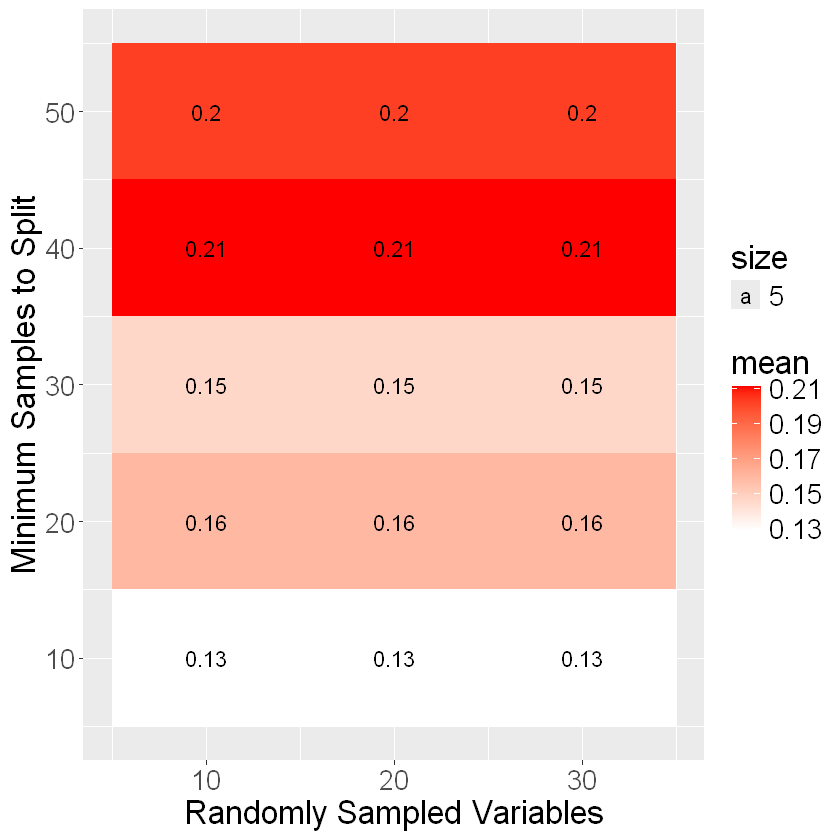

In [ ]:
# plot accuracies of all values of hyperparameters

ggplot(model_tuning_accuracies) +
    geom_tile(aes(x=tree_depth, y=min_n, fill=mean)) +
    geom_text(aes(x=tree_depth, y=min_n, label=round(mean, 2), size=5)) +
    labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title='Accuracy') +
    theme(text = element_text(size=20)) +
    scale_fill_gradient(low="white", high="red")

# Print best hyperparameter values
best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(tree_depth, min_n)
print("Best hyperparameters: (mtry, min_n)")
print(best_params)

In [ ]:
# retrain model on best parameters
best_params <- model_tuning %>%
  select_best()
print("Best Parameters:")
print(best_params)

model <- workflow() %>%
    add_recipe(recipe) %>%
    add_model(model_tuning_spec) %>%
    finalize_workflow(best_params) %>%
    last_fit(train_test_split)

# model

Warning message in select_best(.):
"No value of `metric` was given; "roc_auc" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
  tree_depth min_n .config         
       <dbl> <dbl> <chr>           
1         10    50 pre0_mod05_post0


→ A | warning: ✖ No observations were detected in `truth` for levels: 117, 118, and 119.
               ℹ Computation will proceed by ignoring those levels.

There were issues with some computations   A: x1

There were issues with some computations   A: x1





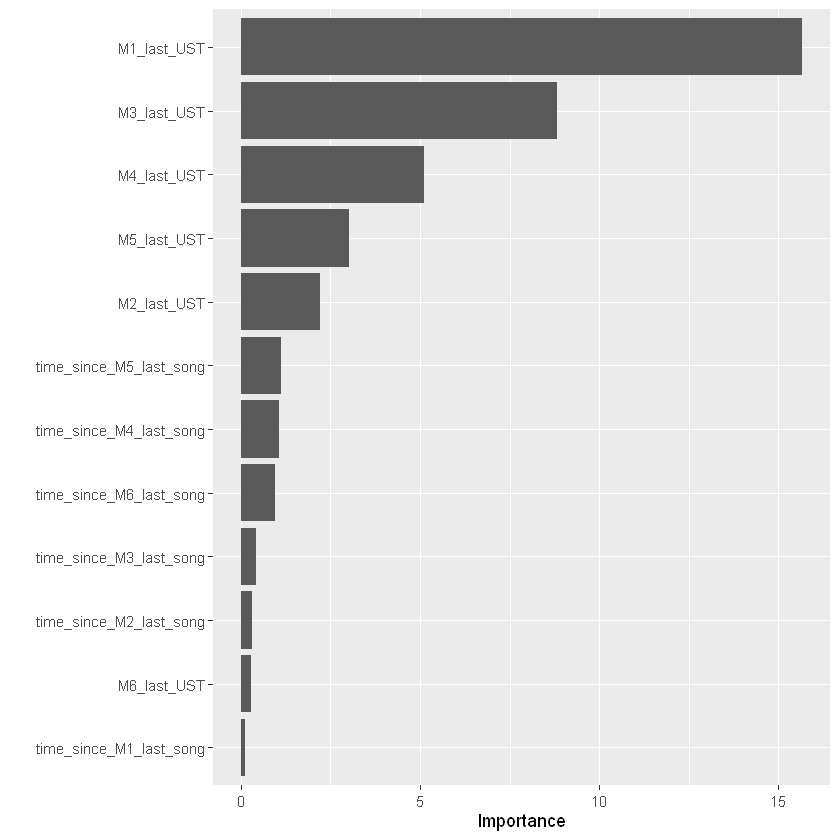

In [ ]:
model %>% extract_fit_engine() %>% vip(num_features=20)

In [ ]:
png("ust_tree.png", width = 1600, height = 800, res = 300)
model %>% extract_fit_engine() %>% rpart.plot(extra = 101, type=3, tweak=0.75)
dev.off() # Close the PNG device

Warning message:
"Cannot retrieve the data used to build the model (model.frame: object '..y' not found).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE."
Warning message:
"All boxes will be white (the box.palette argument will be ignored) because
the number of classes in the response 14 is greater than length(box.palette) 6.
To silence this warning use box.palette=0 or trace=-1."


pdf 
  2

In [ ]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
test_predictions <- model %>% extract_workflow() %>% predict(test_data) %>%
    bind_cols(test_data)

In [ ]:
# test_predictions

In [ ]:
# Accuracy, precision, recall
test_predictions %>% metrics(truth = UST, estimate = .pred_class)
test_predictions %>% precision(truth = UST, estimate = .pred_class, event_level = "second") # Calculated for each class in a non-binary classifer, Precision = correct positive predictions / total positive predictions
test_predictions %>% recall(truth = UST, estimate = .pred_class, event_level = "second") # Calculated for each class in a non-binary classifier, Recall = correct positive predictions / total positive test set observations

.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
accuracy,multiclass,0.2204724
kap,multiclass,0.1024415


Warning message:
"While computing multiclass `precision()`, some levels had no predicted events
(i.e. `true_positive + false_positive = 0`).
Precision is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of true events actually occurred for each
problematic event level:
'12': 2, '13': 8, '17': 9, '116': 1, '117': 0, '118': 0, '119': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
precision,macro,0.2163118


Warning message:
"While computing multiclass `recall()`, some levels had no true events (i.e.
`true_positive + false_negative = 0`).
Recall is undefined in this case, and those levels will be removed from the
averaged result.
Note that the following number of predicted events actually occurred for each
problematic event level:
'117': 0, '118': 0, '119': 0"


.metric,.estimator,.estimate
<chr>,<chr>,<dbl>
recall,macro,0.1635749


In [ ]:
test_predictions %>% pull(UST) %>% levels()
confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
confusion_matrix

[1] "3"   "5"   "8"   "9"   "10"  "12"  "13"  "17"  "21"  "29"  "116" "117"
[13] "118" "119"

          Truth
Prediction 3 5 8 9 10 12 13 17 21 29 116 117 118 119
       3   5 0 1 2  1  0  2  0  0  3   0   0   0   0
       5   1 2 2 3  0  0  2  1  0  0   0   0   0   0
       8   7 0 7 2  4  1  2  3  1  1   0   0   0   0
       9   4 3 6 7  2  0  1  3  2  3   0   0   0   0
       10  0 0 0 1  2  0  0  1  2  2   1   0   0   0
       12  0 0 0 0  0  0  0  0  0  0   0   0   0   0
       13  0 0 0 0  0  0  0  0  0  0   0   0   0   0
       17  0 0 0 0  0  0  0  0  0  0   0   0   0   0
       21  1 2 1 3  2  1  1  0  4  4   0   0   0   0
       29  3 0 2 4  2  0  0  1  2  1   0   0   0   0
       116 0 0 0 0  0  0  0  0  0  0   0   0   0   0
       117 0 0 0 0  0  0  0  0  0  0   0   0   0   0
       118 0 0 0 0  0  0  0  0  0  0   0   0   0   0
       119 0 0 0 0  0  0  0  0  0  0   0   0   0   0